<a href="https://colab.research.google.com/github/malakhaggage2020-afk/my-app-project-/blob/main/project1_c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## preprocessing


In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [69]:
# Option 1: Run this cell to upload the file manually from your local machine
# from google.colab import files
# uploaded = files.upload()

# Option 2: If the file is on GitHub, download it directly using wget
!wget -q https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

# Read the dataset
import pandas as pd
df = pd.read_csv("Telco-Customer-Churn.csv")

In [70]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [72]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## EDA

####  check Categorical columns

In [73]:
print(df.Partner.value_counts()) # label encoder
print(df.PhoneService.value_counts())# label encoder
print(df.Dependents.value_counts())# label encoder
print(df.gender.value_counts())# label encoder
print(df.PaperlessBilling.value_counts())#label encoder
print(df.Churn.value_counts()) # target (label encoder)






Partner
No     3641
Yes    3402
Name: count, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
gender
Male      3555
Female    3488
Name: count, dtype: int64
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [74]:
print(df.MultipleLines.value_counts()) # onehotencoder
print(df.InternetService.value_counts()) # onehotencoder
print(df.OnlineSecurity.value_counts())#onehotencoder
print(df.OnlineBackup.value_counts())#onehotencoder
print(df.DeviceProtection.value_counts())#onehotencoder
print(df.TechSupport.value_counts())#onehotencoder
print(df.StreamingTV.value_counts())#onehotencoder
print(df.PaymentMethod.value_counts())#onehotencoder
print(df.StreamingMovies.value_counts())#onehotencoder



MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64
StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, d

In [75]:
print(df.Contract.value_counts()) # ordinal encoder

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


#### check outliers

<Axes: xlabel='MonthlyCharges'>

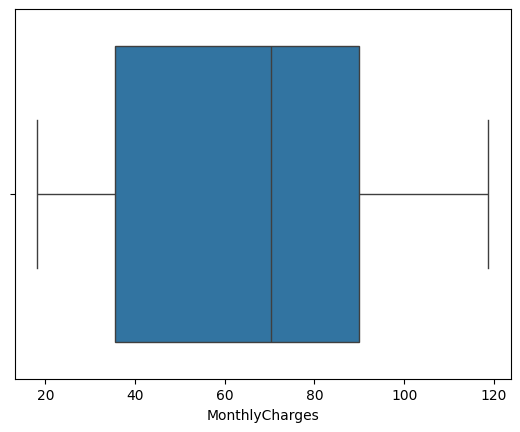

In [76]:
sns.boxplot(data = df,x='MonthlyCharges')

<Axes: xlabel='tenure'>

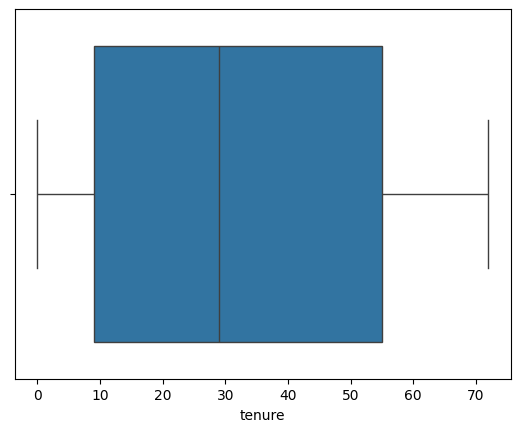

In [77]:
sns.boxplot(data = df,x='tenure')

<Axes: xlabel='SeniorCitizen'>

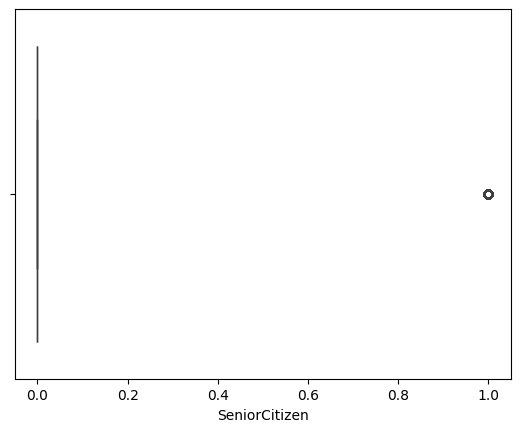

In [78]:
sns.boxplot(data=df,x='SeniorCitizen')
# Do you think we should remove these outliers, or would that be a bad idea because that would leave us with only one value, which is zero?

#### check nulls

In [79]:
str_cols = df.select_dtypes(include='object').columns
df[str_cols] = df[str_cols].apply(lambda s: s.str.strip())
df = df.replace('', np.nan)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.drop(columns=['customerID'])


In [80]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [81]:
df.TotalCharges.fillna(0,inplace=True)

/tmp/ipykernel_1352/3796041264.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df.TotalCharges.fillna(0,inplace=True)


In [82]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


#### 2.6 Check Duplicates

In [83]:
df.duplicated().sum()

np.int64(22)

<Axes: xlabel='Churn', ylabel='count'>

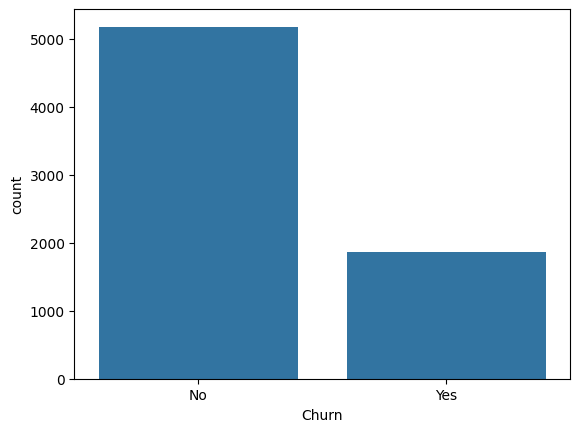

In [84]:
sns.countplot(x='Churn',data= df)

###  Data Splitting

In [85]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [86]:
x = df.drop(columns='Churn')
y = df.Churn

In [87]:
x.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [88]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,
                                                random_state=42)

In [89]:
x_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
2142,Female,0,No,Yes,21,Yes,No,DSL,Yes,No,Yes,No,No,Yes,One year,No,Mailed check,64.85,1336.80
1623,Female,0,No,No,54,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),97.20,5129.45
6074,Male,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,23.45,23.45
1362,Male,0,No,No,4,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.20,237.95
6754,Male,0,No,Yes,0,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,Two year,Yes,Bank transfer (automatic),61.90,0.00


#####  Encoding

In [90]:
print(df.Contract.value_counts()) # ordinal encoder

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


In [91]:
from sklearn.preprocessing import OrdinalEncoder

enc = OrdinalEncoder(categories = [['Month-to-month', 'One year','Two year']])

x_train.Contract= enc.fit_transform(x_train[['Contract']])
x_test.Contract= enc.transform(x_test[['Contract']])

In [92]:
from sklearn.preprocessing import LabelEncoder

binary_cols = ['Partner', 'PhoneService', 'Dependents', 'gender', 'PaperlessBilling']

x_train = x_train.copy()
x_test = x_test.copy()

encoders = {}
for col in binary_cols:
    le = LabelEncoder()
    x_train[col] = le.fit_transform(x_train[col])
    x_test[col] = le.transform(x_test[col])
    encoders[col] = le

le_y = LabelEncoder()
y_train = le_y.fit_transform(y_train)
y_test = le_y.transform(y_test)


In [93]:
print('x_train' ,x_train.shape)
print('y_train' ,y_train.shape)
print('x_test' ,x_test.shape)
print('y_test' ,y_train.shape)



x_train (5634, 19)
y_train (5634,)
x_test (1409, 19)
y_test (5634,)


In [94]:
x_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
2142,0,0,0,1,21,1,No,DSL,Yes,No,Yes,No,No,Yes,1.0,0,Mailed check,64.85,1336.80
1623,0,0,0,0,54,1,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,2.0,1,Bank transfer (automatic),97.20,5129.45
6074,1,0,1,0,1,0,No phone service,DSL,No,No,No,No,No,No,0.0,1,Electronic check,23.45,23.45
1362,1,0,0,0,4,1,No,Fiber optic,No,No,No,No,No,No,0.0,1,Electronic check,70.20,237.95
6754,1,0,0,1,0,1,Yes,DSL,Yes,Yes,No,Yes,No,No,2.0,1,Bank transfer (automatic),61.90,0.00


In [95]:
from sklearn.preprocessing import OneHotEncoder

ohe_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV',
            'PaymentMethod', 'StreamingMovies']

ohe = OneHotEncoder(drop='first', sparse_output=False)

train_ohe = pd.DataFrame(
    ohe.fit_transform(x_train[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=x_train.index
)

test_ohe = pd.DataFrame(
    ohe.transform(x_test[ohe_cols]),
    columns=ohe.get_feature_names_out(ohe_cols),
    index=x_test.index
)

x_train = pd.concat([x_train.drop(columns=ohe_cols), train_ohe], axis=1)
x_test = pd.concat([x_test.drop(columns=ohe_cols), test_ohe], axis=1)

print(x_train.shape, x_test.shape)


(5634, 29) (1409, 29)


In [96]:
x_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,...,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,StreamingMovies_No internet service,StreamingMovies_Yes
2142,0,0,0,1,21,1,1.0,0,64.85,1336.80,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1623,0,0,0,0,54,1,2.0,1,97.20,5129.45,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
6074,1,0,1,0,1,0,0.0,1,23.45,23.45,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1362,1,0,0,0,4,1,0.0,1,70.20,237.95,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
6754,1,0,0,1,0,1,2.0,1,61.90,0.00,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### scaling

In [97]:
from sklearn.preprocessing import StandardScaler

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

#### Imbalancing

<Axes: xlabel='Churn', ylabel='count'>

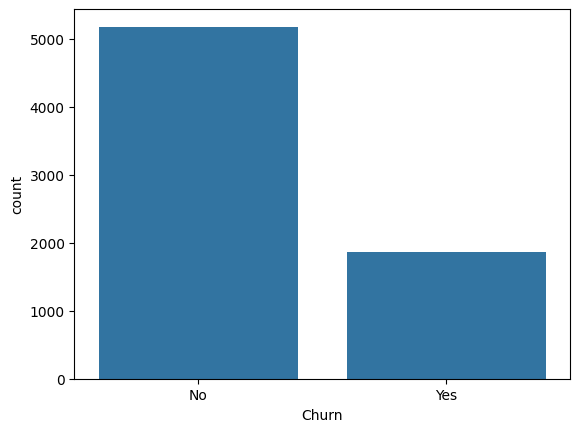

In [98]:
sns.countplot(x='Churn',data= df)

<Axes: ylabel='count'>

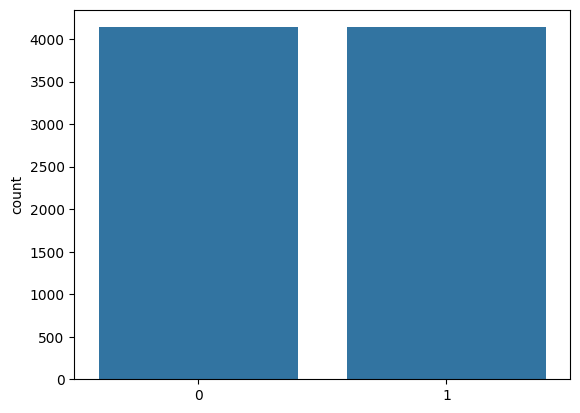

In [99]:
from imblearn.over_sampling import SMOTE
smote =SMOTE(random_state=0)
x_train,y_train = smote.fit_resample(x_train,y_train)
sns.countplot(x=y_train)

In [100]:
x_train.duplicated().sum()

np.int64(36)

In [101]:
x_train.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,...,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,StreamingMovies_No internet service,StreamingMovies_Yes
0,0,0,0,1,-0.465683,1,1.0,0,-0.000474,-0.419925,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,0,0,0,0,0.885537,1,2.0,1,1.074754,1.256017,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1,0,1,0,-1.284605,0,0.0,1,-1.376499,-1.000283,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1,0,0,0,-1.161766,1,0.0,1,0.177346,-0.905497,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1,0,0,1,-1.325551,1,2.0,1,-0.098524,-1.010646,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [102]:
print(x_train.isna().sum().sum(), x_test.isna().sum().sum())
print(x_train.dtypes.value_counts())
print(list(x_train.columns) == list(x_test.columns))
print(x_train.shape, x_test.shape, len(y_train), len(y_test))

0 0
float64    23
int64       6
Name: count, dtype: int64
True
(8276, 29) (1409, 29) 8276 1409


In [103]:
print(x_train[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().loc[['mean', 'std']])

        tenure  MonthlyCharges  TotalCharges
mean -0.185950        0.102283     -0.101352
std   0.981176        0.964920      0.968615


الداتا بقت نضيفة وكلها رقمية، ومقسّمة لـ train و test من غير data leakage، والأعمدة الرقمية متقيّسة، والـ imbalance اتعالج على الـ train بس. الداتا جاهزة لـ Step 2: تدريب النماذج وتقييمها، ويُفضَّل فيه التقييم بـ Recall و F1 و ROC-AUC للـ class 1 (Churn) مش بالـ Accuracy بس.

## 1- Logistic Regression

In [104]:
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression()
LR.fit(x_train, y_train)
y_pred = LR.predict(x_test)


In [105]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.7501774308019872

              precision    recall  f1-score   support

          No       0.92      0.73      0.81      1036
         Yes       0.52      0.82      0.63       373

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

ROC-AUC: 0.8576358338422683


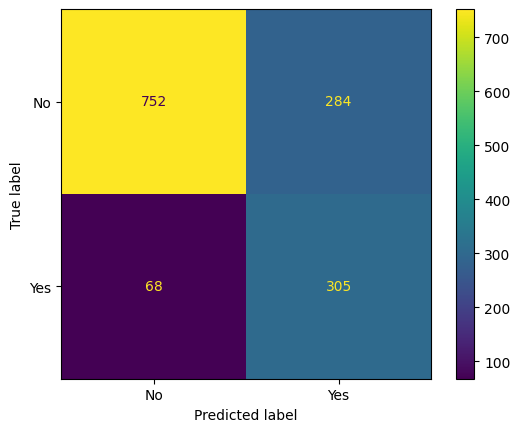

In [106]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
print(classification_report(y_test, y_pred, target_names=['No', 'Yes']))
print("ROC-AUC:", roc_auc_score(y_test, LR.predict_proba(x_test)[:, 1]))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['No', 'Yes']).plot()

## 2- Support Vector Machine (SVM)

In [107]:
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix)

svm = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm.fit(x_train, y_train)

y_pred = svm.predict(x_test)
y_proba = svm.predict_proba(x_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_proba))

print("\n", classification_report(y_test, y_pred, target_names=['No', 'Yes']))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy : 0.7615330021291696
Precision: 0.5334538878842676
Recall   : 0.7908847184986595
F1-score : 0.6371490280777538
ROC-AUC  : 0.8420029086919167

               precision    recall  f1-score   support

          No       0.91      0.75      0.82      1036
         Yes       0.53      0.79      0.64       373

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409

Confusion Matrix:
 [[778 258]
 [ 78 295]]


In [108]:
results = []
for kernel in ['linear', 'rbf']:
    m = SVC(kernel=kernel, probability=True, random_state=42)
    m.fit(x_train, y_train)
    pred = m.predict(x_test)
    proba = m.predict_proba(x_test)[:, 1]
    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
    })

print(pd.DataFrame(results).round(3))

   Kernel  Accuracy  Precision  Recall     F1  ROC-AUC
0  linear     0.742      0.508   0.839  0.633    0.858
1     rbf     0.762      0.533   0.791  0.637    0.842


## 3-K-Nearest Neighbors (KNN)

In [109]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.7104329311568488


In [110]:
model = KNeighborsClassifier()
params = {'n_neighbors': list(range(1,30)),
          'p': [1,2]}


In [111]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(model,params,cv=5,scoring='accuracy')
grid_search.fit(x_train,y_train)
knn_best = KNeighborsClassifier(n_neighbors=27, p=1)
knn_best.fit(x_train,y_train)
y_pred = knn_best.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.71611071682044


In [112]:
acc= []
for k in range(1,30):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train,y_train)
    y_pred = knn.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    acc.append(accuracy)
    print(f'k={k} , accuracy={accuracy}')


k=1 , accuracy=0.7260468417317246
k=2 , accuracy=0.7480482611781405
k=3 , accuracy=0.7033356990773598
k=4 , accuracy=0.7437899219304471
k=5 , accuracy=0.7104329311568488
k=6 , accuracy=0.7331440738112136
k=7 , accuracy=0.7189496096522356
k=8 , accuracy=0.7345635202271115
k=9 , accuracy=0.716820440028389
k=10 , accuracy=0.7338537970191625
k=11 , accuracy=0.7125621007806955
k=12 , accuracy=0.7288857345635202
k=13 , accuracy=0.7132718239886444
k=14 , accuracy=0.7203690560681334
k=15 , accuracy=0.7026259758694109
k=16 , accuracy=0.7189496096522356
k=17 , accuracy=0.7004968062455642
k=18 , accuracy=0.7196593328601846
k=19 , accuracy=0.7047551454932577
k=20 , accuracy=0.7146912704045423
k=21 , accuracy=0.6983676366217175
k=22 , accuracy=0.7132718239886444
k=23 , accuracy=0.7026259758694109
k=24 , accuracy=0.7111426543647977
k=25 , accuracy=0.6933995741660752
k=26 , accuracy=0.7054648687012065
k=27 , accuracy=0.6969481902058198
k=28 , accuracy=0.7075940383250532
k=29 , accuracy=0.696948190205

In [113]:
max(acc)

0.7480482611781405

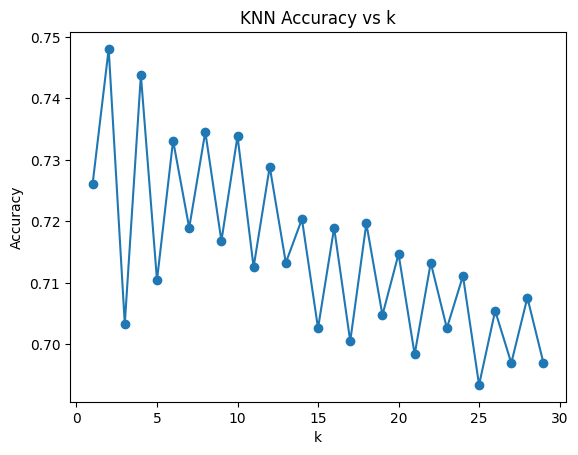

In [114]:
plt.plot(range(1,30),acc,marker='o')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs k')
plt.show()

In [115]:
knn_best = KNeighborsClassifier(n_neighbors=16)
knn_best.fit(x_train,y_train)
y_pred = knn_best.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)

In [116]:
accuracy

0.7189496096522356

In [117]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.68      0.78      1036
           1       0.48      0.83      0.61       373

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.69      1409
weighted avg       0.80      0.72      0.74      1409



## 4- Decision Tree (DT)

In [118]:
from sklearn.tree import DecisionTreeClassifier
model.fit(x_train,y_train)
y_pred_train =  model.predict(x_train)
y_pred = model.predict(x_test)
print('Train classification_report')
print(classification_report(y_train,y_pred_train))
print('------------')
print('test classification_report')
print(classification_report(y_test,y_pred))

Train classification_report
              precision    recall  f1-score   support

           0       0.95      0.76      0.85      4138
           1       0.80      0.96      0.87      4138

    accuracy                           0.86      8276
   macro avg       0.88      0.86      0.86      8276
weighted avg       0.88      0.86      0.86      8276

------------
test classification_report
              precision    recall  f1-score   support

           0       0.89      0.69      0.78      1036
           1       0.47      0.76      0.58       373

    accuracy                           0.71      1409
   macro avg       0.68      0.73      0.68      1409
weighted avg       0.78      0.71      0.73      1409



In [119]:
print("Train accuracy:", dt.score(x_train, y_train))
print("Test accuracy :", dt.score(x_test, y_test))

Train accuracy: 0.7768245529241179
Test accuracy : 0.7430801987224982


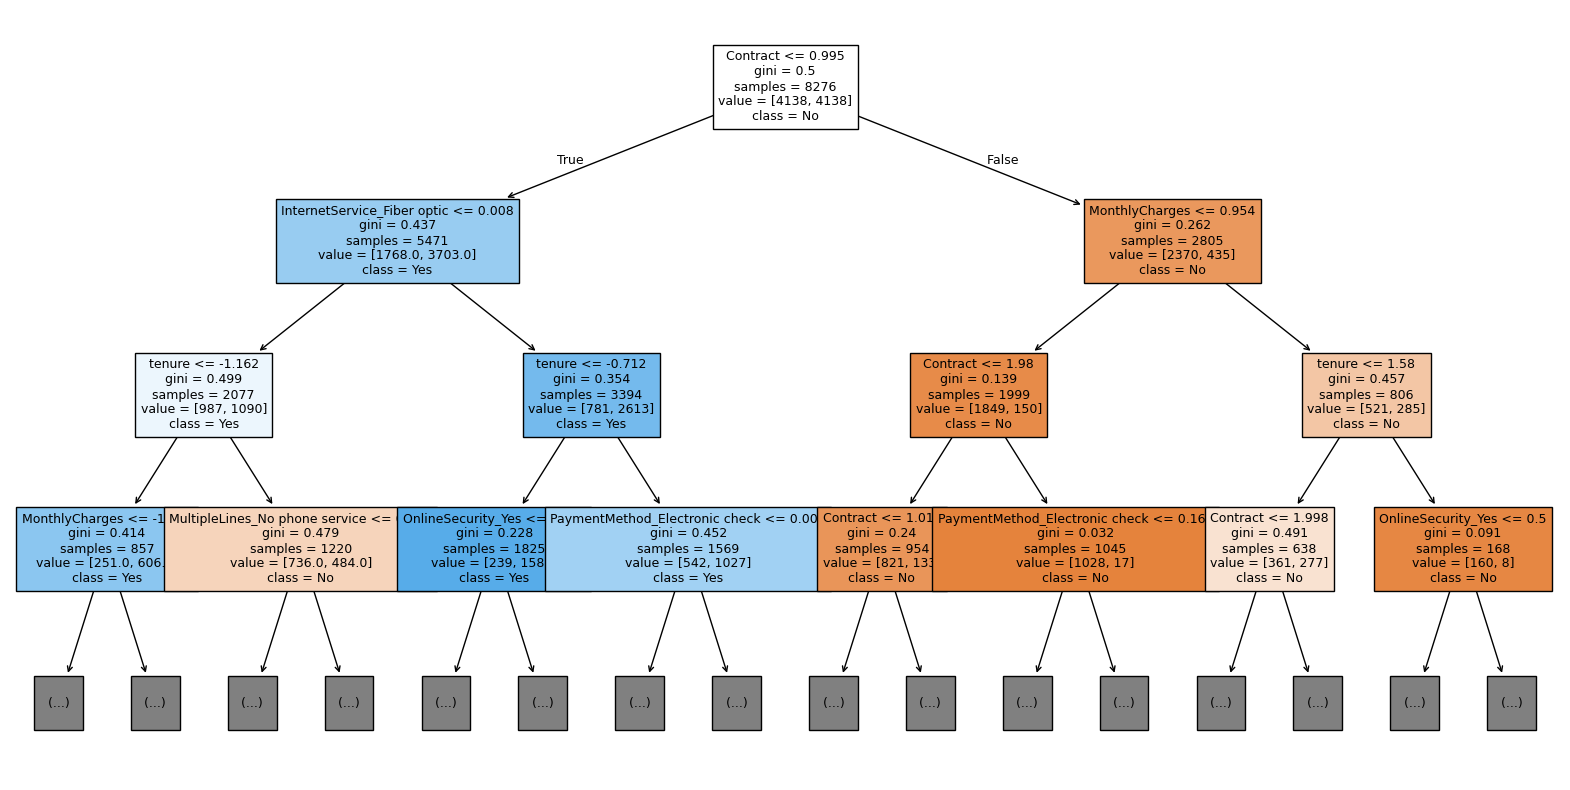

In [120]:
from sklearn import tree

dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42)
dt.fit(x_train, y_train)

plt.figure(figsize=(20, 10), dpi=100)
tree.plot_tree(
    dt,
    filled=True,
    feature_names=x_train.columns,
    class_names=['No', 'Yes'],
    max_depth=3,
    fontsize=9
)
plt.show()

In [121]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [5, 10, 20],
    'criterion': ['gini', 'entropy']
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                    scoring='f1', cv=5, n_jobs=-1)
grid.fit(x_train, y_train)

best_dt = grid.best_estimator_
print(grid.best_params_)

{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5}


## 5- Random Forest (RF)

In [122]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)
y_pred_train =  rf.predict(x_train)
y_pred = rf.predict(x_test)

print('Train classification_report')

print(classification_report(y_train,y_pred_train))
print('------------')
print('test classification_report')

print(classification_report(y_test,y_pred))

Train classification_report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4138
           1       1.00      1.00      1.00      4138

    accuracy                           1.00      8276
   macro avg       1.00      1.00      1.00      8276
weighted avg       1.00      1.00      1.00      8276

------------
test classification_report
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1036
           1       0.59      0.61      0.60       373

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



In [124]:
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [5, 8, 12],
    'min_samples_leaf': [5, 10, 20],
    'max_features': ['sqrt']
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid, scoring='recall', cv=3, n_jobs=-1
)
grid.fit(x_train, y_train)

print("Best params:", grid.best_params_)

best_rf = grid.best_estimator_
y_pred_train = best_rf.predict(x_train)
y_pred = best_rf.predict(x_test)

print('Train'); print(classification_report(y_train, y_pred_train))
print('Test');  print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, best_rf.predict_proba(x_test)[:, 1]))

Best params: {'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 100}
Train
              precision    recall  f1-score   support

           0       0.91      0.84      0.88      4138
           1       0.85      0.92      0.89      4138

    accuracy                           0.88      8276
   macro avg       0.88      0.88      0.88      8276
weighted avg       0.88      0.88      0.88      8276

Test
              precision    recall  f1-score   support

           0       0.90      0.80      0.85      1036
           1       0.57      0.76      0.65       373

    accuracy                           0.79      1409
   macro avg       0.74      0.78      0.75      1409
weighted avg       0.81      0.79      0.79      1409

ROC-AUC: 0.8582129141780617


In [ ]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8,
                            min_samples_leaf=10, random_state=42, n_jobs=-1)